# 📘 MODULE 3 — TEXT NORMALIZATION & PREPROCESSING
## 3.3 Regular Expressions

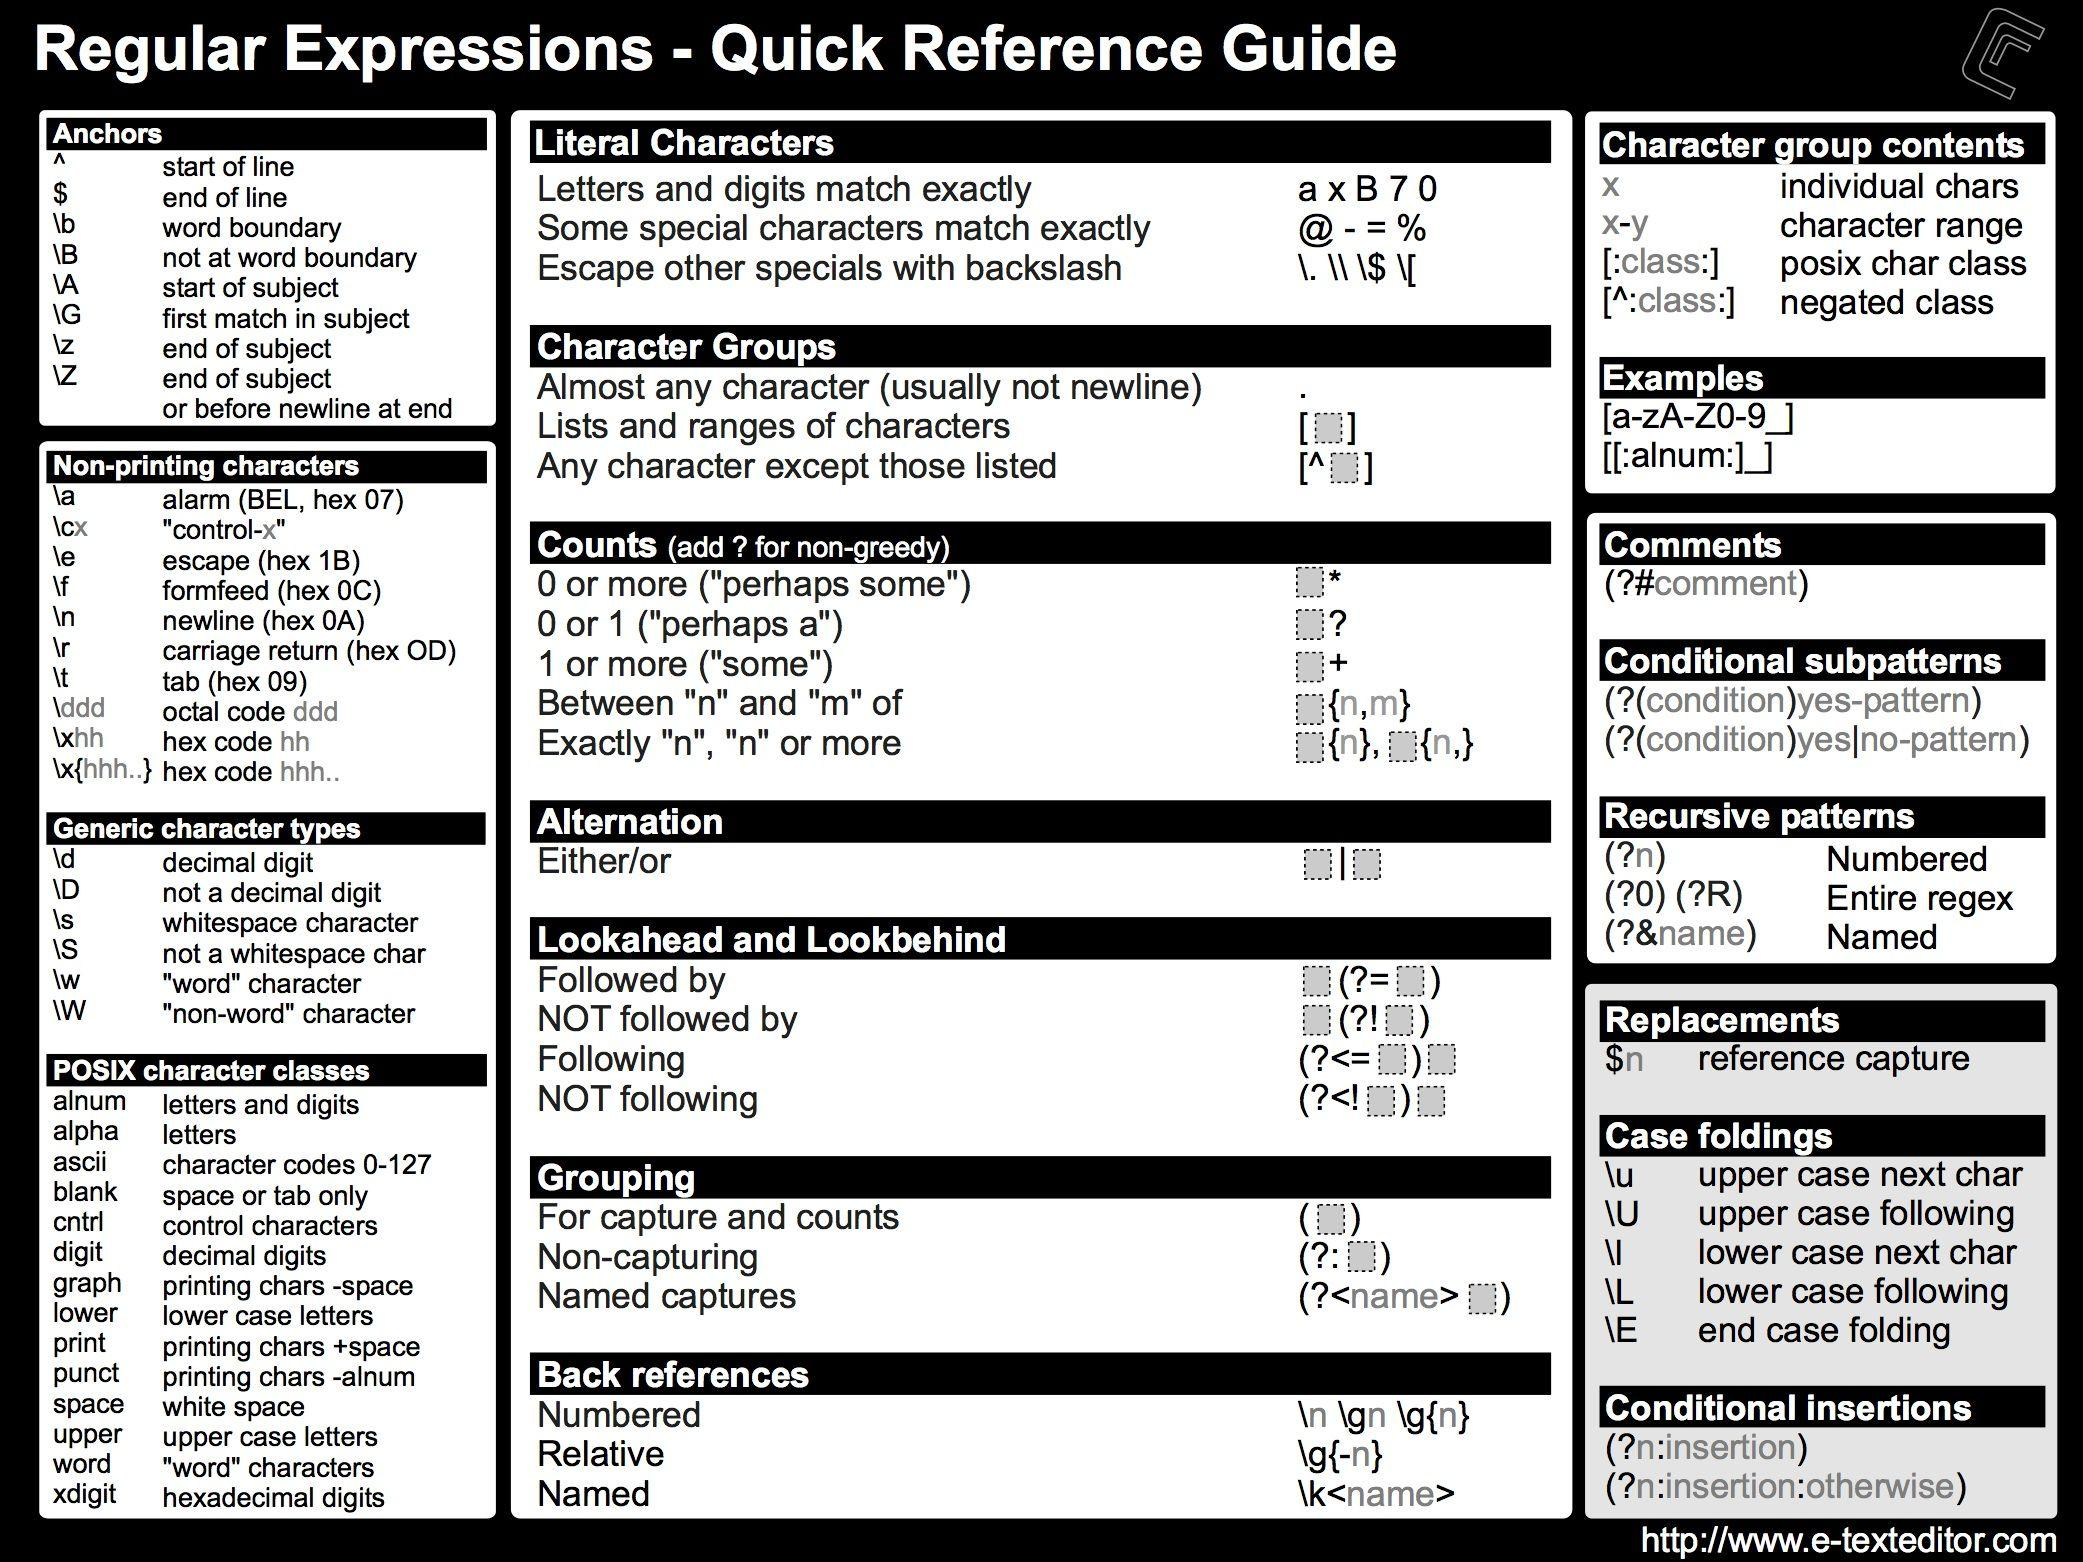

**Regular Expressions (Regex)** are patterns used to **search, identify, extract, replace, or validate specific patterns in text**.

In NLP, regex is particularly useful during **text cleaning and preprocessing**.

Python provides the `re` module for regular expressions. [Python documentation](https://docs.python.org/3/library/re.html?highlight=s\&utm_source=chatgpt.com)

---

## 1. Basic Regex Building Blocks

Before working with NLP patterns, understand these:

| Pattern | Meaning | Example |
|---|---|---|
| `.` | Any character except newline | `c.t` → `cat` |
| `\d` | Digit | `123` |
| `\w` | Unicode word character | `hello` |
| `\s` | Whitespace | spaces, tabs |
| `\D` | Not a digit | `abc` |
| `\W` | Not a word character | `@`, `!` |
| `\S` | Not whitespace | `hello` |
| `^` | Start of string/line | `^Hello` |
| `$` | End of string/line | `world$` |

Python's `re` module treats `\d`, `\s`, and `\w` according to Unicode by default for Python `str` patterns. [Python documentation](https://docs.python.org/3/library/re.html?highlight=s\&utm_source=chatgpt.com)

### Quantifiers

```text
*       → 0 or more
+       → 1 or more
?       → 0 or 1
{n}     → exactly n
{n,m}   → between n and m
```

Example:

```text
go+
```

matches:

```text
go
goo
gooo
goooo
```



---

# 2. Python `re` Module

```python
import re
```

Important functions:

```python
re.search()   # find a pattern
re.match()    # match at beginning
re.findall()  # find all matches
re.sub()      # replace matches
re.split()    # split using a pattern
```

Example:

```python
import re

text = "I have 25 apples and 10 oranges."

numbers = re.findall(r"\d+", text)

print(numbers)
```

Output:

```text
['25', '10']
```

The Python `re` module provides these matching and substitution operations. [Python documentation](https://docs.python.org/3/library/re.html?highlight=s\&utm_source=chatgpt.com)

---

# 3. URLs

A practical URL pattern:

```python
url_pattern = r"https?://\S+"
```

Example:

```python
text = "Visit https://example.com for more information."

urls = re.findall(url_pattern, text)

print(urls)
```

Output:

```text
['https://example.com']
```

### Replace URLs

```python
text = re.sub(r"https?://\S+", "<URL>", text)

print(text)
```

Output:

```text
Visit <URL> for more information.
```

### Breakdown

```text
https?    → http OR https
://       → literal characters
\S+       → one or more non-whitespace characters
```

---

# 4. Emails

A practical pattern for many common email addresses:

```python
email_pattern = r"[\w.-]+@[\w.-]+\.\w+"
```

Example:

```python
text = "Contact me at yuva19@gmail.com"

emails = re.findall(email_pattern, text)

print(emails)
```

Output:

```text
['yuva19@gmail.com']
```

### Structure

```text
[\w.-]+    → username
@          → @ symbol
[\w.-]+    → domain
\.         → dot
\w+        → domain extension
```

⚠️ **Important:** Email syntax is more complicated than this practical pattern. For NLP preprocessing, simple extraction patterns are often sufficient; don't assume a regex is a complete email validator.

---

# 5. Numbers

Use:

```python
r"\d+"
```

to find sequences of digits.

Example:

```python
text = "I bought 3 phones for 50000 rupees."

numbers = re.findall(r"\d+", text)

print(numbers)
```

Output:

```text
['3', '50000']
```

### Replace numbers

```python
text = re.sub(r"\d+", "<NUM>", text)
```

Result:

```text
I bought <NUM> phones for <NUM> rupees.
```

### Decimal numbers

```python
r"\d+(?:\.\d+)?"
```

Matches:

```text
25
25.5
100
100.75
```

---

# 6. Special Characters

To find characters that are **not word characters or whitespace**:

```python
r"[^\w\s]"
```

Example:

```python
text = "Hello!!! NLP @ 2026"

result = re.sub(r"[^\w\s]", "", text)

print(result)
```

Output:

```text
Hello NLP  2026
```

### Breakdown

```text
[ ... ]     → character class
^           → NOT
\w          → word character
\s          → whitespace
```

So:

```text
[^\w\s]
```

means:

> Match anything that is neither a word character nor whitespace.

---

# 7. HTML Tags

A simple practical pattern for basic HTML tags:

```python
html_pattern = r"<[^>]+>"
```

Example:

```python
text = "<p>This is <b>great</b>!</p>"

clean = re.sub(html_pattern, "", text)

print(clean)
```

Output:

```text
This is great!
```

### ⚠️ Important

For simple HTML cleaning, regex can demonstrate the concept, but for **real HTML parsing**, use an HTML parser such as BeautifulSoup rather than trying to handle every possible HTML structure with regex.

---

# 8. Repeated Spaces

Regex makes whitespace normalization very easy.

```python
text = "This    is   an   NLP   example."

text = re.sub(r"\s+", " ", text)

print(text)
```

Output:

```text
This is an NLP example.
```

### Pattern

```text
\s+
```

means:

> One or more whitespace characters.

This can handle spaces, tabs, and newlines because Python's `\s` includes Unicode whitespace for `str` patterns. [Python documentation](https://docs.python.org/3/library/re.html?highlight=s\&utm_source=chatgpt.com)

---

# 9. Custom Patterns

This is where regex becomes powerful.

Suppose we want to find hashtags:

```python
pattern = r"#\w+"
```

Example:

```python
text = "I love #NLP and #MachineLearning"

hashtags = re.findall(pattern, text)

print(hashtags)
```

Output:

```text
['#NLP', '#MachineLearning']
```

### Mentions

```python
pattern = r"@\w+"
```

```text
"Hello @yuva and @john"
```

→

```text
['@yuva', '@john']
```

---

# 🔥 Practical NLP Cleaning Example

Real-world text might look like:

```text
text = """
<p>OMG!!! This product is AMAZING 😍</p>
Visit https://example.com
Contact: user@gmail.com
Price: ₹2500
"""
```

We can combine regex operations:

```python
import re

# Remove HTML
text = re.sub(r"<[^>]+>", " ", text)

# Replace URLs
text = re.sub(r"https?://\S+", " <URL> ", text)

# Replace emails
text = re.sub(r"[\w.-]+@[\w.-]+\.\w+", " <EMAIL> ", text)

# Replace numbers
text = re.sub(r"\d+", " <NUM> ", text)

# Normalize whitespace
text = re.sub(r"\s+", " ", text).strip()

print(text)
```

Possible output:

```text
OMG!!! This product is AMAZING 😍 Visit <URL> Contact: <EMAIL> Price: ₹<NUM>
```

Notice that **emojis and punctuation were preserved** because we didn't remove them.

That's intentional: preprocessing should depend on the NLP task.

---

# 🧠 Regex Cheat Sheet



| Regex | Meaning | NLP Use |
|---|---|---|
| `\d+` | One or more digits | Numbers |
| `\s+` | One or more spaces/whitespace | Whitespace normalization |
| `\w+` | One or more word characters | Words/usernames |
| `\S+` | One or more non-whitespace | URLs |
| `https?://\S+` | HTTP/HTTPS URL | URL extraction |
| `[\w.-]+@[\w.-]+\.\w+` | Practical email pattern | Email extraction |
| `<[^>]+>` | Basic HTML tag pattern | HTML removal |
| `[^\w\s]` | Non-word, non-space characters | Special characters |
| `#\w+` | Hashtag | Social-media NLP |
| `@\w+` | Mention | Social-media NLP |
| `\d+(?:\.\d+)?` | Integer/decimal | Numeric extraction |

---

## ⭐ What You Actually Need to Master

For NLP preprocessing, you **do not need to memorize hundreds of regex patterns**.

Master these:

```text
\d      → digits
\w      → word characters
\s      → whitespace
.       → any character
[]      → character class
[^]     → negated character class
+       → one or more
*       → zero or more
?       → optional
{n,m}   → repetition range
^       → start
$       → end
()      → grouping
|       → OR
```

And be comfortable with:

```python
re.findall()
re.search()
re.sub()
re.split()
```

---